In [3]:
!wget -q -O imagenet10.zip "https://www.kaggle.com/api/v1/datasets/download/liusha249/imagenet10"
!unzip -q imagenet10.zip -d imagenet10
!find imagenet10 -maxdepth 3 -type d | head -40

imagenet10
imagenet10/imagenet-10
imagenet10/imagenet-10/n04254680
imagenet10/imagenet-10/n07747607
imagenet10/imagenet-10/n02690373
imagenet10/imagenet-10/n02056570
imagenet10/imagenet-10/n03095699
imagenet10/imagenet-10/n02692877
imagenet10/imagenet-10/n02128757
imagenet10/imagenet-10/n02085936
imagenet10/imagenet-10/n04467665
imagenet10/imagenet-10/n04285008


In [4]:
from pathlib import Path
from PIL import Image
from collections import Counter

ROOT = Path("imagenet10/imagenet-10")

files = []
for ext in ["*.jpg", "*.jpeg", "*.png", "*.JPEG"]:
    files.extend(ROOT.rglob(ext))

print("Total images:", len(files))

class_counts = Counter(p.parent.name for p in files)

for cls, count in sorted(class_counts.items()):
    print(cls, count)

print("\nSample images:")
for p in files[:10]:
    try:
        img = Image.open(p)
        print(p, img.size, img.mode)
    except:
        pass

Total images: 13000
n02056570 1300
n02085936 1300
n02128757 1300
n02690373 1300
n02692877 1300
n03095699 1300
n04254680 1300
n04285008 1300
n04467665 1300
n07747607 1300

Sample images:
imagenet10/imagenet-10/n04254680/n04254680_2442.JPEG (500, 344) RGB
imagenet10/imagenet-10/n04254680/n04254680_8633.JPEG (500, 375) RGB
imagenet10/imagenet-10/n04254680/n04254680_120.JPEG (353, 500) RGB
imagenet10/imagenet-10/n04254680/n04254680_1541.JPEG (333, 500) RGB
imagenet10/imagenet-10/n04254680/n04254680_7501.JPEG (500, 333) RGB
imagenet10/imagenet-10/n04254680/n04254680_4951.JPEG (500, 328) L
imagenet10/imagenet-10/n04254680/n04254680_1286.JPEG (142, 158) RGB
imagenet10/imagenet-10/n04254680/n04254680_3131.JPEG (500, 375) L
imagenet10/imagenet-10/n04254680/n04254680_1813.JPEG (500, 500) RGB
imagenet10/imagenet-10/n04254680/n04254680_15224.JPEG (486, 487) RGB


In [5]:
import random
from collections import defaultdict
from pathlib import Path

SEED = 42
random.seed(SEED)

ROOT = Path("imagenet10/imagenet-10")

class_files = defaultdict(list)

for ext in ["*.jpg", "*.jpeg", "*.png", "*.JPEG"]:
    for p in ROOT.rglob(ext):
        class_files[p.parent.name].append(p)

classes = sorted(class_files.keys())
class_to_idx = {cls: i for i, cls in enumerate(classes)}

train_samples = []
val_samples = []

for cls in classes:
    cls_files = class_files[cls].copy()
    random.shuffle(cls_files)

    train_files = cls_files[:1000]
    val_files = cls_files[1000:1300]

    train_samples.extend(
        [(p, class_to_idx[cls]) for p in train_files]
    )

    val_samples.extend(
        [(p, class_to_idx[cls]) for p in val_files]
    )

random.shuffle(train_samples)
random.shuffle(val_samples)

print("Classes:", classes)
print("Train:", len(train_samples))
print("Validation:", len(val_samples))

Classes: ['n02056570', 'n02085936', 'n02128757', 'n02690373', 'n02692877', 'n03095699', 'n04254680', 'n04285008', 'n04467665', 'n07747607']
Train: 10000
Validation: 3000


In [6]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class ImageDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [7]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

In [8]:
train_dataset = ImageDataset(train_samples, train_transform)
val_dataset = ImageDataset(val_samples, val_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

Train: 10000
Validation: 3000


In [9]:
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = resnet18(weights=ResNet18_Weights.DEFAULT)

model.fc = nn.Linear(
    model.fc.in_features,
    10
)

model = model.to(device)

print("Device:", device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s]


Device: cuda


In [10]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU detected")

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
CUDA version: 12.8


In [11]:
print(device)
print(len(train_dataset))
print(len(val_dataset))

cuda
10000
3000


In [12]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=8
)

best_val_acc = 0.0

for epoch in range(8):
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    scheduler.step()

    print(
        f"Epoch {epoch+1}/8 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "imagenet10_resnet18_best.pth")

print("Best validation accuracy:", best_val_acc)

Epoch 1/8 | Train Loss: 0.1952 | Train Acc: 0.9534 | Val Loss: 0.0658 | Val Acc: 0.9843
Epoch 2/8 | Train Loss: 0.0392 | Train Acc: 0.9893 | Val Loss: 0.0595 | Val Acc: 0.9787
Epoch 3/8 | Train Loss: 0.0206 | Train Acc: 0.9947 | Val Loss: 0.0488 | Val Acc: 0.9847
Epoch 4/8 | Train Loss: 0.0117 | Train Acc: 0.9979 | Val Loss: 0.0398 | Val Acc: 0.9863
Epoch 5/8 | Train Loss: 0.0069 | Train Acc: 0.9990 | Val Loss: 0.0414 | Val Acc: 0.9883
Epoch 6/8 | Train Loss: 0.0053 | Train Acc: 0.9993 | Val Loss: 0.0418 | Val Acc: 0.9860
Epoch 7/8 | Train Loss: 0.0036 | Train Acc: 0.9999 | Val Loss: 0.0404 | Val Acc: 0.9893
Epoch 8/8 | Train Loss: 0.0040 | Train Acc: 0.9997 | Val Loss: 0.0403 | Val Acc: 0.9887
Best validation accuracy: 0.9893333333333333


In [13]:
model.load_state_dict(
    torch.load(
        "imagenet10_resnet18_best.pth",
        map_location=device
    )
)

model.eval()

print("Best model loaded")

Best model loaded


In [14]:
import io
import numpy as np
import pandas as pd
from PIL import Image

QUALITIES = [10,20,30,40,50,60,70,80,90]

def jpeg_compress(image, quality):
    buffer = io.BytesIO()

    image.save(
        buffer,
        format="JPEG",
        quality=quality,
        subsampling=0
    )

    size_bytes = buffer.tell()

    buffer.seek(0)
    compressed = Image.open(buffer).convert("RGB")

    return compressed, size_bytes

def predict_image(image):
    tensor = val_transform(image)
    tensor = tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(tensor)
        probabilities = torch.softmax(logits, dim=1)

    return logits[0], probabilities[0]

In [15]:
TEST_N = 100

results = []

for image_id in range(TEST_N):

    path, true_label = val_samples[image_id]

    original = Image.open(path).convert("RGB")

    original_logits, original_probs = predict_image(original)

    original_loss = nn.CrossEntropyLoss()(
        original_logits.unsqueeze(0),
        torch.tensor([true_label], device=device)
    ).item()

    original_prediction = original_probs.argmax().item()
    original_correct = int(original_prediction == true_label)

    for quality in QUALITIES:

        compressed, size_bytes = jpeg_compress(
            original,
            quality
        )

        logits, probs = predict_image(compressed)

        loss = nn.CrossEntropyLoss()(
            logits.unsqueeze(0),
            torch.tensor([true_label], device=device)
        ).item()

        prediction = probs.argmax().item()

        results.append({
            "image_id": image_id,
            "path": str(path),
            "class": true_label,
            "quality": quality,
            "size_bytes": size_bytes,
            "loss": loss,
            "true_probability": probs[true_label].item(),
            "correct": int(prediction == true_label),
            "original_loss": original_loss,
            "original_true_probability": original_probs[true_label].item(),
            "original_correct": original_correct
        })

    if (image_id + 1) % 10 == 0:
        print(f"Processed {image_id + 1}/{TEST_N}")

Processed 10/100
Processed 20/100
Processed 30/100
Processed 40/100
Processed 50/100
Processed 60/100
Processed 70/100
Processed 80/100
Processed 90/100
Processed 100/100


In [16]:
df = pd.DataFrame(results)

print("Rows:", len(df))
print(df.head())

Rows: 900
   image_id                                               path  class  \
0         0  imagenet10/imagenet-10/n07747607/n07747607_173...      9   
1         0  imagenet10/imagenet-10/n07747607/n07747607_173...      9   
2         0  imagenet10/imagenet-10/n07747607/n07747607_173...      9   
3         0  imagenet10/imagenet-10/n07747607/n07747607_173...      9   
4         0  imagenet10/imagenet-10/n07747607/n07747607_173...      9   

   quality  size_bytes      loss  true_probability  correct  original_loss  \
0       10        7756  0.000133          0.999867        1       0.000069   
1       20       10569  0.000119          0.999881        1       0.000069   
2       30       13190  0.000092          0.999908        1       0.000069   
3       40       15460  0.000058          0.999942        1       0.000069   
4       50       17759  0.000057          0.999943        1       0.000069   

   original_true_probability  original_correct  
0                   0.999931     

In [17]:
image_id = 0

print(
    df[df["image_id"] == image_id][
        [
            "quality",
            "size_bytes",
            "loss",
            "loss_increase",
            "true_probability",
            "correct"
        ]
    ].to_string(index=False)
)

KeyError: "['loss_increase'] not in index"

In [18]:
df["loss_increase"] = df["loss"] - df["original_loss"]

df["probability_drop"] = (
    df["original_true_probability"]
    - df["true_probability"]
)

df["prediction_flip"] = (
    df["correct"] != df["original_correct"]
).astype(int)

print("Derived columns added")

Derived columns added


In [19]:
image_id = 0

print(
    df[df["image_id"] == image_id][
        [
            "quality",
            "size_bytes",
            "loss",
            "loss_increase",
            "true_probability",
            "correct"
        ]
    ].to_string(index=False)
)

 quality  size_bytes     loss  loss_increase  true_probability  correct
      10        7756 0.000133       0.000064          0.999867        1
      20       10569 0.000119       0.000050          0.999881        1
      30       13190 0.000092       0.000023          0.999908        1
      40       15460 0.000058      -0.000011          0.999942        1
      50       17759 0.000057      -0.000012          0.999943        1
      60       20260 0.000058      -0.000011          0.999942        1
      70       24012 0.000061      -0.000008          0.999939        1
      80       31047 0.000064      -0.000005          0.999936        1
      90       45908 0.000065      -0.000004          0.999935        1


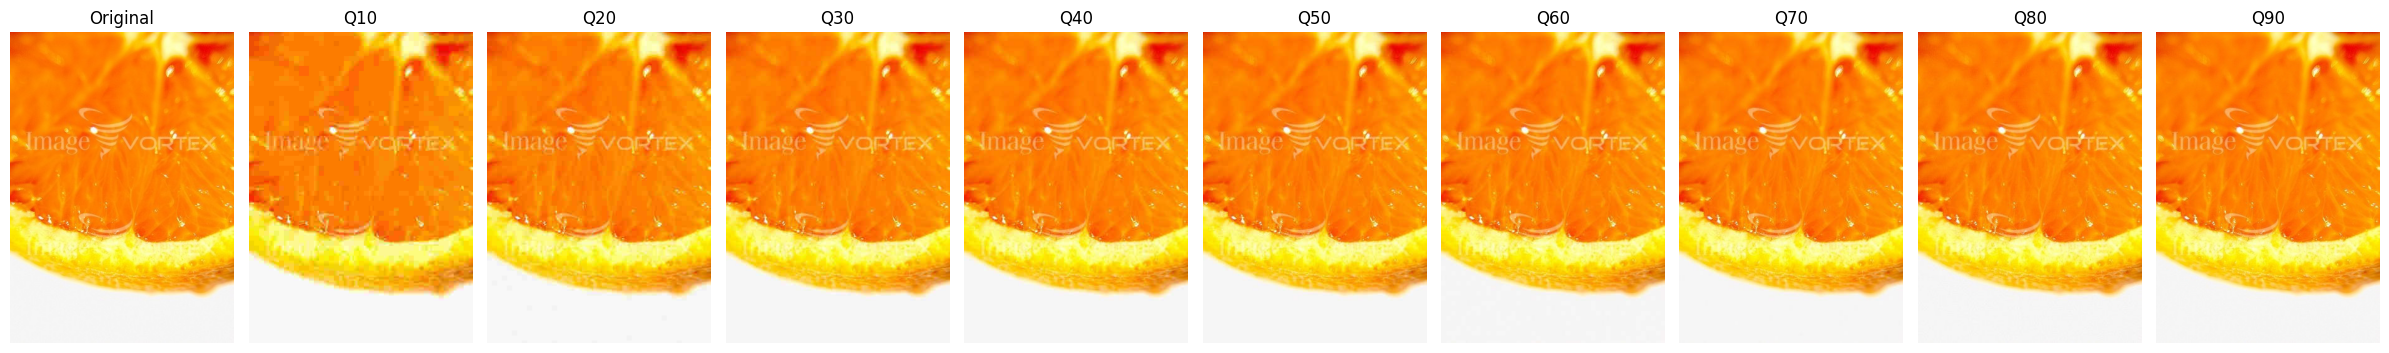

In [20]:
import matplotlib.pyplot as plt
from PIL import Image
import io

image_id = 0

row = df[df["image_id"] == image_id].sort_values("quality")
image_path = row.iloc[0]["path"]

original = Image.open(image_path).convert("RGB")

plt.figure(figsize=(24, 4))

plt.subplot(1, 10, 1)
plt.imshow(original)
plt.title("Original")
plt.axis("off")

for idx, quality in enumerate(QUALITIES, start=2):
    compressed, _ = jpeg_compress(original, quality)

    plt.subplot(1, 10, idx)
    plt.imshow(compressed)
    plt.title(f"Q{quality}")
    plt.axis("off")

plt.tight_layout()
plt.show()

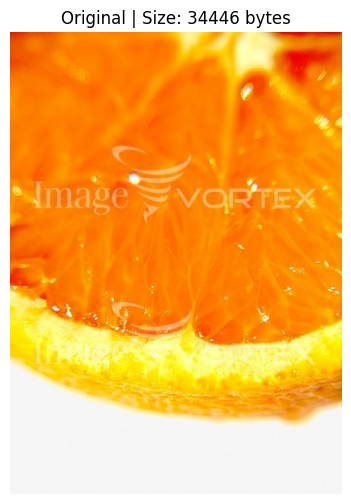

ORIGINAL
Size: 34446 bytes
Loss: 0.00006891
True probability: 0.99993110
Prediction: 9
Correct: True

COMPRESSED RESULTS
--------------------------------------------------------------------------------------------------------------
 Quality       Size           Loss    Loss Increase      True Prob      Prob Drop  Correct
--------------------------------------------------------------------------------------------------------------
       1       5951     3.50742388       3.50735497     0.02997403     0.96995706        0
       2       5952     3.65831232       3.65824342     0.02577598     0.97415512        0
       5       6424     0.00359746       0.00352856     0.99640900     0.00352210        1
      10       7756     0.00013340       0.00006450     0.99986660     0.00006449        1
      20      10569     0.00011934       0.00005043     0.99988067     0.00005043        1
      30      13190     0.00009168       0.00002277     0.99990833     0.00002277        1
      40      15460 

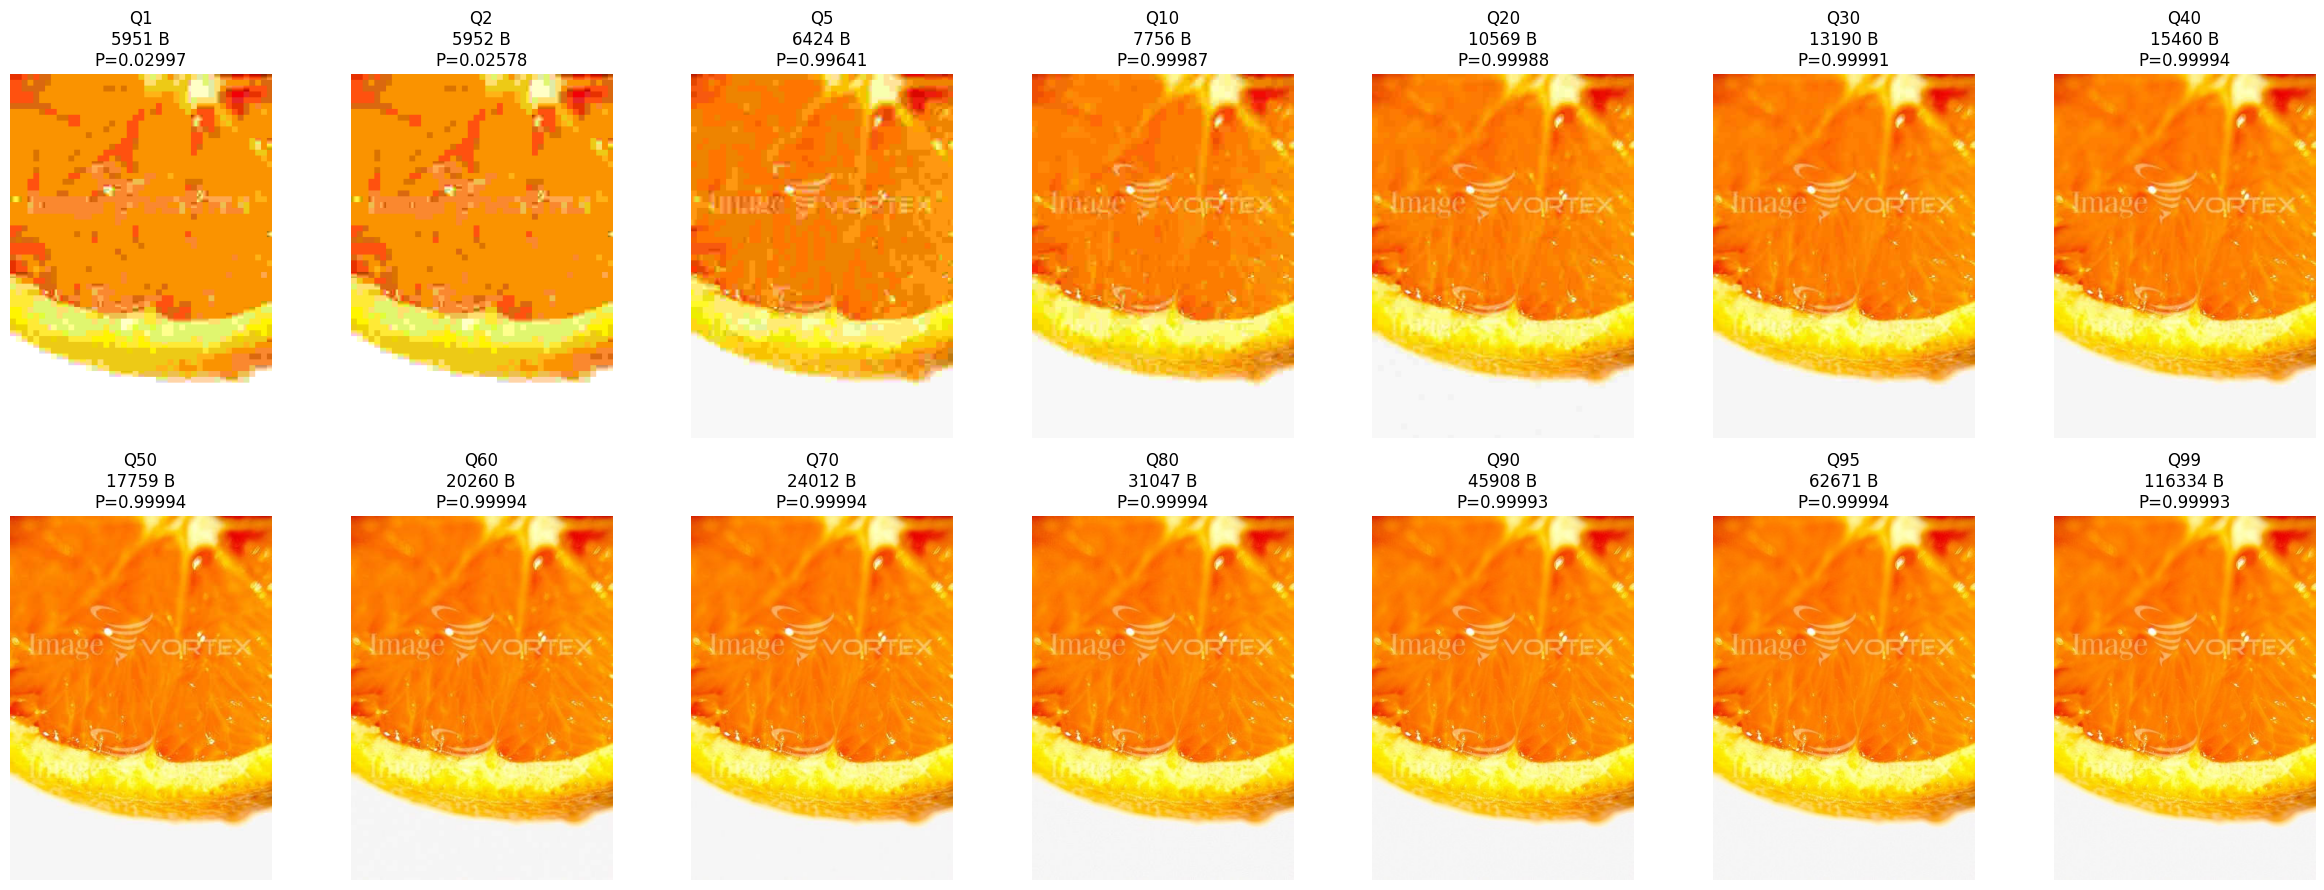

In [21]:
import io
import matplotlib.pyplot as plt
from PIL import Image

# Test only one image
image_id = 0
image_row = df[df["image_id"] == image_id].iloc[0]
image_path = image_row["path"]
label = int(image_row["class"])

original = Image.open(image_path).convert("RGB")

# Qualities including very aggressive and very high quality
QUALITIES = [1, 2, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 99]

results = []

# Original prediction
original_logits, original_probs = predict_image(original)
original_loss = -torch.log(original_probs[label] + 1e-12).item()
original_prob = original_probs[label].item()
original_pred = original_logits.argmax().item()

# Original image
plt.figure(figsize=(8, 6))
plt.imshow(original)
plt.title(f"Original | Size: {len(open(image_path, 'rb').read())} bytes")
plt.axis("off")
plt.show()

# Compress and test
for quality in QUALITIES:
    buffer = io.BytesIO()
    original.save(buffer, format="JPEG", quality=quality, subsampling=0)
    size_bytes = buffer.tell()

    buffer.seek(0)
    compressed = Image.open(buffer).convert("RGB")

    logits, probs = predict_image(compressed)

    loss = -torch.log(probs[label] + 1e-12).item()
    true_probability = probs[label].item()
    pred = logits.argmax().item()
    correct = int(pred == label)

    results.append({
        "quality": quality,
        "size_bytes": size_bytes,
        "loss": loss,
        "loss_increase": loss - original_loss,
        "true_probability": true_probability,
        "probability_drop": original_prob - true_probability,
        "prediction": pred,
        "correct": correct
    })

# Print original result
print("ORIGINAL")
print(f"Size: {len(open(image_path, 'rb').read())} bytes")
print(f"Loss: {original_loss:.8f}")
print(f"True probability: {original_prob:.8f}")
print(f"Prediction: {original_pred}")
print(f"Correct: {original_pred == label}")

print("\nCOMPRESSED RESULTS")
print("-" * 110)
print(f"{'Quality':>8} {'Size':>10} {'Loss':>14} {'Loss Increase':>16} {'True Prob':>14} {'Prob Drop':>14} {'Correct':>8}")
print("-" * 110)

for r in results:
    print(
        f"{r['quality']:>8} "
        f"{r['size_bytes']:>10} "
        f"{r['loss']:>14.8f} "
        f"{r['loss_increase']:>16.8f} "
        f"{r['true_probability']:>14.8f} "
        f"{r['probability_drop']:>14.8f} "
        f"{r['correct']:>8}"
    )

# Display all compressed versions
fig, axes = plt.subplots(2, 7, figsize=(24, 9))

for ax, quality, r in zip(axes.flat, QUALITIES, results):
    buffer = io.BytesIO()
    original.save(buffer, format="JPEG", quality=quality, subsampling=0)
    buffer.seek(0)
    compressed = Image.open(buffer).convert("RGB")

    ax.imshow(compressed)
    ax.set_title(
        f"Q{quality}\n"
        f"{r['size_bytes']} B\n"
        f"P={r['true_probability']:.5f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
import io
import random
import matplotlib.pyplot as plt
from PIL import Image

# Pick a random image from the validation/test samples
image_path, label = random.choice(test_samples)

original = Image.open(image_path).convert("RGB")
label = int(label)

QUALITIES = [1, 2, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 99]

# Original prediction
original_logits, original_probs = predict_image(original)
original_loss = -torch.log(original_probs[label] + 1e-12).item()
original_prob = original_probs[label].item()
original_pred = original_logits.argmax().item()

original_size = len(open(image_path, "rb").read())

print("RANDOM IMAGE")
print(f"Path: {image_path}")
print(f"Class: {label}")
print(f"Original size: {original_size} bytes")
print(f"Original loss: {original_loss:.8f}")
print(f"Original true probability: {original_prob:.8f}")
print(f"Original prediction: {original_pred}")
print(f"Original correct: {original_pred == label}")

# Show original
plt.figure(figsize=(7, 5))
plt.imshow(original)
plt.title("Original")
plt.axis("off")
plt.show()

results = []

# Test different JPEG qualities
for quality in QUALITIES:
    buffer = io.BytesIO()
    original.save(
        buffer,
        format="JPEG",
        quality=quality,
        subsampling=0
    )

    size_bytes = buffer.tell()

    buffer.seek(0)
    compressed = Image.open(buffer).convert("RGB")

    logits, probs = predict_image(compressed)

    loss = -torch.log(probs[label] + 1e-12).item()
    true_probability = probs[label].item()
    pred = logits.argmax().item()
    correct = int(pred == label)

    results.append({
        "quality": quality,
        "size_bytes": size_bytes,
        "loss": loss,
        "loss_increase": loss - original_loss,
        "true_probability": true_probability,
        "probability_drop": original_prob - true_probability,
        "prediction": pred,
        "correct": correct
    })

# Print results
print("\nCOMPRESSION RESULTS")
print("-" * 115)
print(
    f"{'Quality':>8} "
    f"{'Size':>10} "
    f"{'Loss':>14} "
    f"{'Loss Increase':>16} "
    f"{'True Prob':>14} "
    f"{'Prob Drop':>14} "
    f"{'Prediction':>12} "
    f"{'Correct':>8}"
)
print("-" * 115)

for r in results:
    print(
        f"{r['quality']:>8} "
        f"{r['size_bytes']:>10} "
        f"{r['loss']:>14.8f} "
        f"{r['loss_increase']:>16.8f} "
        f"{r['true_probability']:>14.8f} "
        f"{r['probability_drop']:>14.8f} "
        f"{r['prediction']:>12} "
        f"{r['correct']:>8}"
    )

# Display all compressed versions
fig, axes = plt.subplots(2, 7, figsize=(24, 9))

for ax, quality, r in zip(axes.flat, QUALITIES, results):
    buffer = io.BytesIO()
    original.save(
        buffer,
        format="JPEG",
        quality=quality,
        subsampling=0
    )

    buffer.seek(0)
    compressed = Image.open(buffer).convert("RGB")

    ax.imshow(compressed)
    ax.set_title(
        f"Q{quality}\n"
        f"{r['size_bytes']} B\n"
        f"P={r['true_probability']:.5f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

NameError: name 'test_samples' is not defined

RANDOM IMAGE
Path: imagenet10/imagenet-10/n02056570/n02056570_863.JPEG
Class: 0
Original size: 105376 bytes
Original loss: 0.00076788
Original true probability: 0.99923241
Original prediction: 0
Original correct: True


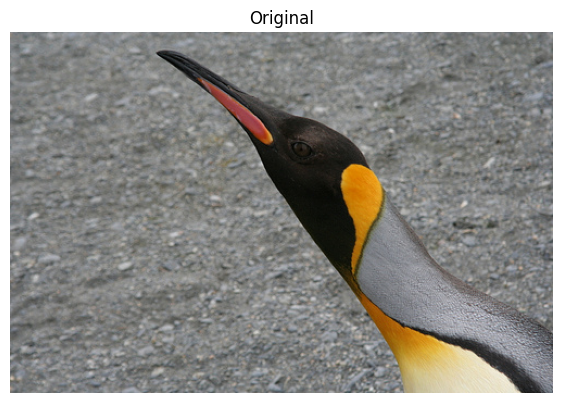


COMPRESSION RESULTS
-------------------------------------------------------------------------------------------------------------------
 Quality       Size           Loss    Loss Increase      True Prob      Prob Drop   Prediction  Correct
-------------------------------------------------------------------------------------------------------------------
       1       5579     7.90929222       7.90852434     0.00036731     0.99886510            5        0
       2       5579     7.88882732       7.88805944     0.00037491     0.99885750            5        0
       5       6621     0.12026419       0.11949631     0.88668615     0.11254627            0        1
      10       9631     0.00339171       0.00262382     0.99661404     0.00261837            0        1
      20      14403     0.00106111       0.00029322     0.99893945     0.00029296            0        1
      30      18093     0.00096737       0.00019949     0.99903309     0.00019932            0        1
      40      21164

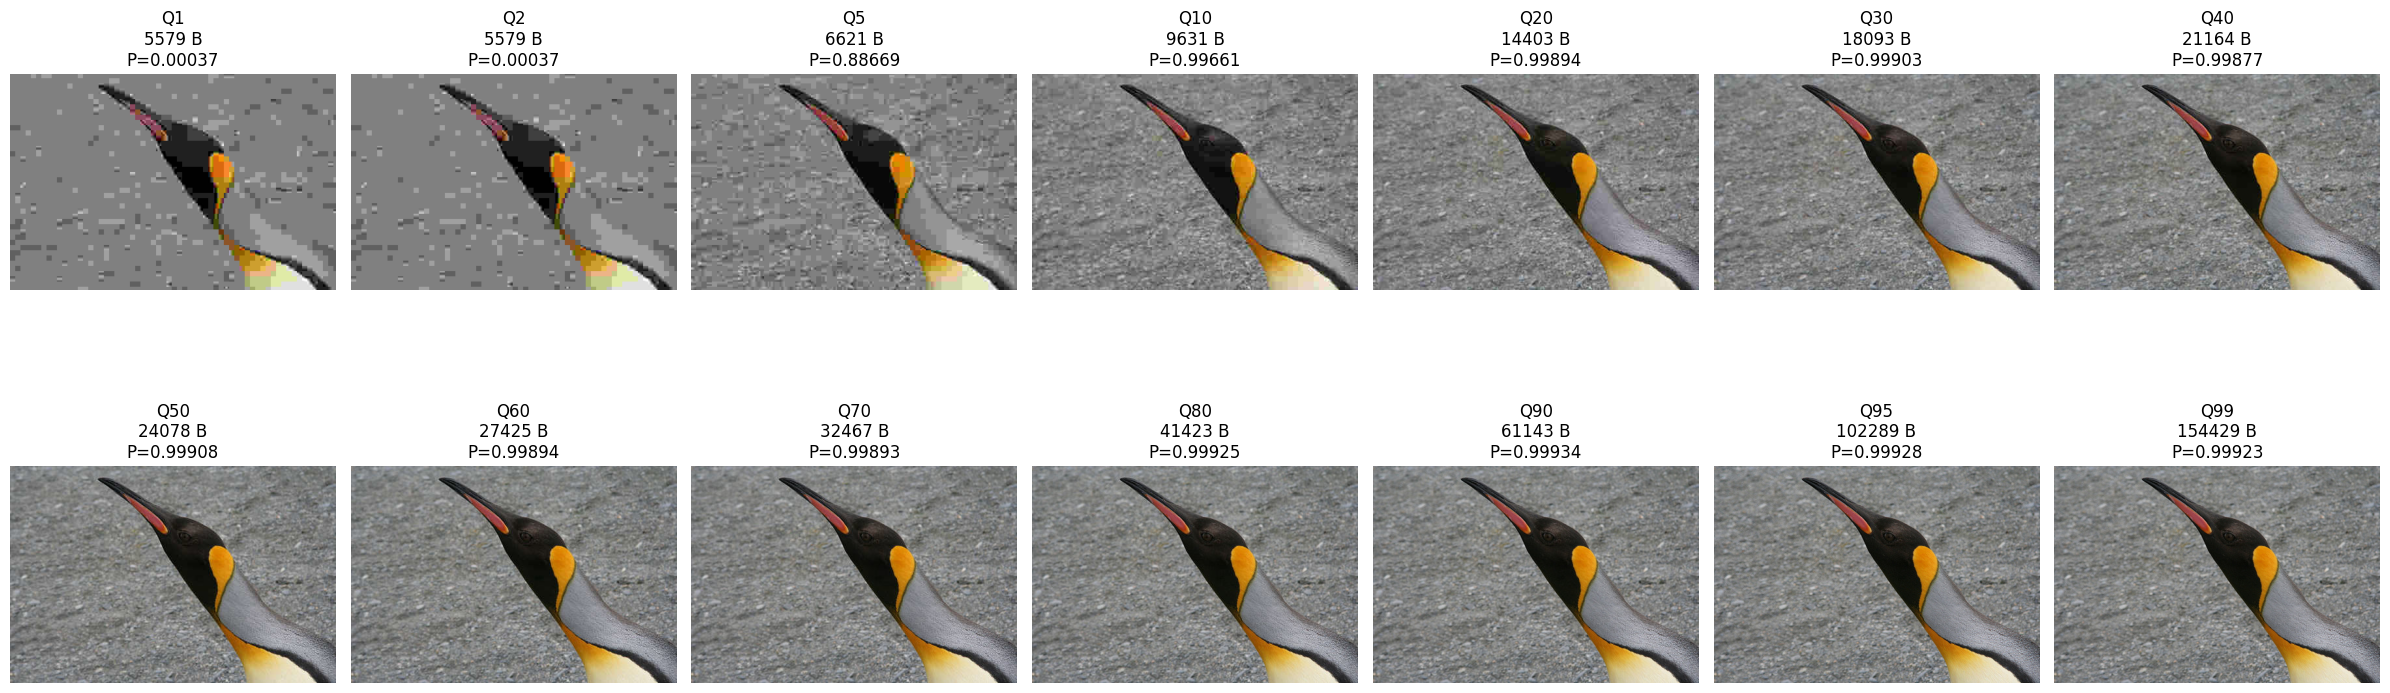

In [23]:
import io
import random
import matplotlib.pyplot as plt
from PIL import Image

# Pick one random image from validation set
image_path, label = random.choice(val_samples)
label = int(label)

original = Image.open(image_path).convert("RGB")

QUALITIES = [1, 2, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 99]

# Original prediction
original_logits, original_probs = predict_image(original)
original_loss = -torch.log(original_probs[label] + 1e-12).item()
original_prob = original_probs[label].item()
original_pred = original_logits.argmax().item()

original_size = len(open(image_path, "rb").read())

print("RANDOM IMAGE")
print(f"Path: {image_path}")
print(f"Class: {label}")
print(f"Original size: {original_size} bytes")
print(f"Original loss: {original_loss:.8f}")
print(f"Original true probability: {original_prob:.8f}")
print(f"Original prediction: {original_pred}")
print(f"Original correct: {original_pred == label}")

# Show original
plt.figure(figsize=(7, 5))
plt.imshow(original)
plt.title("Original")
plt.axis("off")
plt.show()

results = []

# Test compression levels
for quality in QUALITIES:
    buffer = io.BytesIO()

    original.save(
        buffer,
        format="JPEG",
        quality=quality,
        subsampling=0
    )

    size_bytes = buffer.tell()

    buffer.seek(0)
    compressed = Image.open(buffer).convert("RGB")

    logits, probs = predict_image(compressed)

    loss = -torch.log(probs[label] + 1e-12).item()
    true_probability = probs[label].item()
    pred = logits.argmax().item()
    correct = int(pred == label)

    results.append({
        "quality": quality,
        "size_bytes": size_bytes,
        "loss": loss,
        "loss_increase": loss - original_loss,
        "true_probability": true_probability,
        "probability_drop": original_prob - true_probability,
        "prediction": pred,
        "correct": correct
    })

# Print results
print("\nCOMPRESSION RESULTS")
print("-" * 115)
print(
    f"{'Quality':>8} "
    f"{'Size':>10} "
    f"{'Loss':>14} "
    f"{'Loss Increase':>16} "
    f"{'True Prob':>14} "
    f"{'Prob Drop':>14} "
    f"{'Prediction':>12} "
    f"{'Correct':>8}"
)
print("-" * 115)

for r in results:
    print(
        f"{r['quality']:>8} "
        f"{r['size_bytes']:>10} "
        f"{r['loss']:>14.8f} "
        f"{r['loss_increase']:>16.8f} "
        f"{r['true_probability']:>14.8f} "
        f"{r['probability_drop']:>14.8f} "
        f"{r['prediction']:>12} "
        f"{r['correct']:>8}"
    )

# Show all compression levels
fig, axes = plt.subplots(2, 7, figsize=(24, 9))

for ax, quality, r in zip(axes.flat, QUALITIES, results):
    buffer = io.BytesIO()

    original.save(
        buffer,
        format="JPEG",
        quality=quality,
        subsampling=0
    )

    buffer.seek(0)
    compressed = Image.open(buffer).convert("RGB")

    ax.imshow(compressed)
    ax.set_title(
        f"Q{quality}\n"
        f"{r['size_bytes']} B\n"
        f"P={r['true_probability']:.5f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [24]:
import io
import random
import pandas as pd
import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm

# ============================================================
# SETTINGS
# ============================================================

TEST_N = 100

QUALITIES = [
    1, 2, 3, 5, 7, 10, 15, 20,
    30, 40, 50, 60, 70, 80, 90, 95, 99
]

# Randomly select images from validation set
random.seed(42)
experiment_samples = random.sample(val_samples, TEST_N)

# ============================================================
# RUN EXPERIMENT
# ============================================================

results = []

model.eval()

for image_id, (image_path, label) in enumerate(
    tqdm(experiment_samples, desc="Processing images")
):
    label = int(label)

    original = Image.open(image_path).convert("RGB")

    # --------------------------------------------------------
    # Original image prediction
    # --------------------------------------------------------

    original_logits, original_probs = predict_image(original)

    original_loss = -torch.log(
        original_probs[label] + 1e-12
    ).item()

    original_prob = original_probs[label].item()

    original_pred = original_logits.argmax().item()

    original_correct = int(original_pred == label)

    # Actual original file size
    original_size = len(open(image_path, "rb").read())

    # --------------------------------------------------------
    # Compression experiments
    # --------------------------------------------------------

    for quality in QUALITIES:

        buffer = io.BytesIO()

        original.save(
            buffer,
            format="JPEG",
            quality=quality,
            subsampling=0
        )

        size_bytes = buffer.tell()

        buffer.seek(0)

        compressed = Image.open(buffer).convert("RGB")

        # Prediction
        logits, probs = predict_image(compressed)

        loss = -torch.log(
            probs[label] + 1e-12
        ).item()

        true_probability = probs[label].item()

        pred = logits.argmax().item()

        correct = int(pred == label)

        # ----------------------------------------------------
        # Store everything
        # ----------------------------------------------------

        results.append({
            "image_id": image_id,
            "path": str(image_path),
            "class": label,

            "quality": quality,

            "original_size_bytes": original_size,
            "size_bytes": size_bytes,

            "compression_ratio": original_size / size_bytes,

            "loss": loss,
            "original_loss": original_loss,
            "loss_increase": loss - original_loss,

            "true_probability": true_probability,
            "original_true_probability": original_prob,
            "probability_drop": original_prob - true_probability,

            "prediction": pred,
            "original_prediction": original_pred,

            "correct": correct,
            "original_correct": original_correct,

            "prediction_flip": int(
                pred != original_pred
            )
        })

# ============================================================
# DATAFRAME
# ============================================================

df = pd.DataFrame(results)

print("\nExperiment completed.")
print(f"Images tested: {TEST_N}")
print(f"Quality levels: {len(QUALITIES)}")
print(f"Total experiments: {len(df)}")

# ============================================================
# AGGREGATE RESULTS
# ============================================================

summary = df.groupby("quality").agg(
    avg_size_bytes=("size_bytes", "mean"),
    median_size_bytes=("size_bytes", "median"),

    avg_compression_ratio=("compression_ratio", "mean"),

    avg_loss=("loss", "mean"),
    avg_loss_increase=("loss_increase", "mean"),

    avg_true_probability=("true_probability", "mean"),
    avg_probability_drop=("probability_drop", "mean"),

    accuracy=("correct", "mean"),
    prediction_flip_rate=("prediction_flip", "mean")
).reset_index()

print("\n")
print("=" * 120)
print("OVERALL COMPRESSION RESULTS")
print("=" * 120)

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ============================================================
# ADD PERCENTAGES
# ============================================================

summary["accuracy_percent"] = summary["accuracy"] * 100
summary["flip_rate_percent"] = summary["prediction_flip_rate"] * 100

print("\n")
print("=" * 100)
print("IMPORTANT METRICS")
print("=" * 100)

print(
    summary[
        [
            "quality",
            "avg_size_bytes",
            "avg_compression_ratio",
            "avg_loss_increase",
            "avg_probability_drop",
            "accuracy_percent",
            "flip_rate_percent"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ============================================================
# HOW MANY IMAGES ARE ACTUALLY AFFECTED?
# ============================================================

affected = df.groupby("quality").agg(
    images_with_loss_increase=(
        "loss_increase",
        lambda x: (x > 0.001).sum()
    ),

    images_with_large_loss_increase=(
        "loss_increase",
        lambda x: (x > 0.01).sum()
    ),

    images_with_probability_drop=(
        "probability_drop",
        lambda x: (x > 0.01).sum()
    ),

    prediction_flips=(
        "prediction_flip",
        "sum"
    )
).reset_index()

print("\n")
print("=" * 100)
print("IMAGE-LEVEL SENSITIVITY")
print("=" * 100)

print(
    affected.to_string(index=False)
)

# ============================================================
# SAVE RESULTS
# ============================================================

df.to_csv(
    "jpeg_compression_experiment_100_images.csv",
    index=False
)

summary.to_csv(
    "jpeg_compression_summary.csv",
    index=False
)

print("\nResults saved:")
print("jpeg_compression_experiment_100_images.csv")
print("jpeg_compression_summary.csv")

Processing images:   0%|          | 0/100 [00:00<?, ?it/s]


Experiment completed.
Images tested: 100
Quality levels: 17
Total experiments: 1700


OVERALL COMPRESSION RESULTS
 quality  avg_size_bytes  median_size_bytes  avg_compression_ratio  avg_loss  avg_loss_increase  avg_true_probability  avg_probability_drop  accuracy  prediction_flip_rate
       1     7474.890000        6243.000000              15.275582  2.547836           2.461484              0.434789              0.524825  0.470000              0.530000
       2     7476.950000        6244.000000              15.270834  2.553915           2.467563              0.436477              0.523137  0.470000              0.530000
       3     7695.740000        6449.500000              14.792018  1.899074           1.812722              0.532950              0.426664  0.560000              0.440000
       5     8675.440000        7275.500000              12.963338  0.571335           0.484983              0.796036              0.163578  0.800000              0.180000
       7     9746.770000 

In [25]:
import io
import random
import pandas as pd
import torch
from PIL import Image
from tqdm.auto import tqdm

# ============================================================
# SETTINGS
# ============================================================

TEST_N = 1000

QUALITIES = [
    1, 2, 3, 5, 7, 10, 15, 20,
    30, 40, 50, 60, 70, 80, 90, 95, 99
]

random.seed(42)

# Random 1000 images from validation set
experiment_samples = random.sample(val_samples, TEST_N)

model.eval()

results = []

# ============================================================
# EXPERIMENT
# ============================================================

for image_id, (image_path, label) in enumerate(
    tqdm(experiment_samples, desc="Processing images")
):
    label = int(label)

    # --------------------------------------------------------
    # Load original
    # --------------------------------------------------------

    original = Image.open(image_path).convert("RGB")

    original_size = len(open(image_path, "rb").read())

    # --------------------------------------------------------
    # Original prediction
    # --------------------------------------------------------

    original_tensor = val_transform(original).unsqueeze(0).to(device)

    with torch.no_grad():
        original_logits = model(original_tensor)
        original_probs = torch.softmax(original_logits, dim=1)

    original_loss = -torch.log(
        original_probs[0, label] + 1e-12
    ).item()

    original_prob = original_probs[0, label].item()

    original_pred = original_logits.argmax(dim=1).item()

    original_correct = int(original_pred == label)

    # --------------------------------------------------------
    # Create all compressed versions
    # --------------------------------------------------------

    compressed_tensors = []
    compressed_sizes = []

    for quality in QUALITIES:

        buffer = io.BytesIO()

        original.save(
            buffer,
            format="JPEG",
            quality=quality,
            subsampling=0
        )

        size_bytes = buffer.tell()

        buffer.seek(0)

        compressed = Image.open(buffer).convert("RGB")

        tensor = val_transform(compressed)

        compressed_tensors.append(tensor)
        compressed_sizes.append(size_bytes)

    # --------------------------------------------------------
    # Batch prediction for all qualities
    # --------------------------------------------------------

    batch = torch.stack(compressed_tensors).to(device)

    with torch.no_grad():
        logits = model(batch)
        probs = torch.softmax(logits, dim=1)

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    for i, quality in enumerate(QUALITIES):

        loss = -torch.log(
            probs[i, label] + 1e-12
        ).item()

        true_probability = probs[i, label].item()

        pred = logits[i].argmax().item()

        correct = int(pred == label)

        results.append({
            "image_id": image_id,
            "path": str(image_path),
            "class": label,

            "quality": quality,

            "original_size_bytes": original_size,
            "size_bytes": compressed_sizes[i],

            "loss": loss,
            "original_loss": original_loss,
            "loss_increase": loss - original_loss,

            "true_probability": true_probability,
            "original_true_probability": original_prob,
            "probability_drop": original_prob - true_probability,

            "prediction": pred,
            "original_prediction": original_pred,

            "correct": correct,
            "original_correct": original_correct,

            "prediction_flip": int(
                pred != original_pred
            )
        })

# ============================================================
# DATAFRAME
# ============================================================

df_1000 = pd.DataFrame(results)

print("\nExperiment completed.")
print(f"Images tested: {TEST_N}")
print(f"Quality levels: {len(QUALITIES)}")
print(f"Total experiments: {len(df_1000)}")

# ============================================================
# AGGREGATE RESULTS
# ============================================================

summary_1000 = df

Processing images:   0%|          | 0/1000 [00:00<?, ?it/s]


Experiment completed.
Images tested: 1000
Quality levels: 17
Total experiments: 17000


In [26]:
import cv2
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# ============================================================
# 1. FEATURE EXTRACTION
# ============================================================

def extract_features(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Cannot read: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY).astype(np.float32)

    features = {}

    # --------------------------------------------------------
    # IMAGE SIZE / SHAPE
    # --------------------------------------------------------

    features["width"] = w
    features["height"] = h
    features["aspect_ratio"] = w / h
    features["num_pixels"] = w * h

    # --------------------------------------------------------
    # RGB COLOR STATISTICS
    # --------------------------------------------------------

    for i, name in enumerate(["R", "G", "B"]):
        channel = image[:, :, i].astype(np.float32)

        features[f"{name}_mean"] = np.mean(channel)
        features[f"{name}_std"] = np.std(channel)
        features[f"{name}_min"] = np.min(channel)
        features[f"{name}_max"] = np.max(channel)

        p10, p50, p90 = np.percentile(
            channel, [10, 50, 90]
        )

        features[f"{name}_p10"] = p10
        features[f"{name}_p50"] = p50
        features[f"{name}_p90"] = p90

    # --------------------------------------------------------
    # HSV COLOR
    # --------------------------------------------------------

    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV).astype(np.float32)

    for i, name in enumerate(["H", "S", "V"]):
        channel = hsv[:, :, i]

        features[f"{name}_mean"] = np.mean(channel)
        features[f"{name}_std"] = np.std(channel)

    # --------------------------------------------------------
    # LAB COLOR
    # --------------------------------------------------------

    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB).astype(np.float32)

    for i, name in enumerate(["L", "A", "B_lab"]):
        channel = lab[:, :, i]

        features[f"{name}_mean"] = np.mean(channel)
        features[f"{name}_std"] = np.std(channel)

    # --------------------------------------------------------
    # GRAYSCALE / BRIGHTNESS
    # --------------------------------------------------------

    features["gray_mean"] = np.mean(gray)
    features["gray_std"] = np.std(gray)

    p10, p25, p50, p75, p90 = np.percentile(
        gray,
        [10, 25, 50, 75, 90]
    )

    features["gray_p10"] = p10
    features["gray_p25"] = p25
    features["gray_p50"] = p50
    features["gray_p75"] = p75
    features["gray_p90"] = p90

    # --------------------------------------------------------
    # GRAYSCALE ENTROPY
    # --------------------------------------------------------

    hist = cv2.calcHist(
        [gray.astype(np.uint8)],
        [0],
        None,
        [256],
        [0, 256]
    ).flatten()

    hist = hist / (hist.sum() + 1e-12)

    features["gray_entropy"] = -np.sum(
        hist * np.log2(hist + 1e-12)
    )

    # --------------------------------------------------------
    # GRADIENT / EDGE INFORMATION
    # --------------------------------------------------------

    gx = cv2.Sobel(
        gray,
        cv2.CV_32F,
        1,
        0,
        ksize=3
    )

    gy = cv2.Sobel(
        gray,
        cv2.CV_32F,
        0,
        1,
        ksize=3
    )

    magnitude = np.sqrt(
        gx * gx + gy * gy
    )

    features["gradient_mean"] = np.mean(magnitude)
    features["gradient_std"] = np.std(magnitude)
    features["gradient_max"] = np.max(magnitude)
    features["gradient_p90"] = np.percentile(magnitude, 90)

    edges = cv2.Canny(
        gray.astype(np.uint8),
        100,
        200
    )

    features["edge_density"] = np.mean(edges > 0)

    # --------------------------------------------------------
    # DIRECTIONAL EDGES
    # --------------------------------------------------------

    features["horizontal_edge_strength"] = np.mean(
        np.abs(gx)
    )

    features["vertical_edge_strength"] = np.mean(
        np.abs(gy)
    )

    # --------------------------------------------------------
    # LAPLACIAN / SHARPNESS
    # --------------------------------------------------------

    laplacian = cv2.Laplacian(
        gray,
        cv2.CV_32F
    )

    features["laplacian_variance"] = np.var(
        laplacian
    )

    features["laplacian_mean_abs"] = np.mean(
        np.abs(laplacian)
    )

    # --------------------------------------------------------
    # LOCAL TEXTURE
    # --------------------------------------------------------

    local_mean = cv2.blur(
        gray,
        (7, 7)
    )

    local_mean_sq = cv2.blur(
        gray * gray,
        (7, 7)
    )

    local_variance = np.maximum(
        local_mean_sq - local_mean * local_mean,
        0
    )

    local_std = np.sqrt(local_variance)

    features["texture_mean"] = np.mean(local_std)
    features["texture_std"] = np.std(local_std)
    features["texture_p90"] = np.percentile(local_std, 90)

    # --------------------------------------------------------
    # DCT / FREQUENCY FEATURES
    # --------------------------------------------------------

    # Resize grayscale image for consistent DCT computation
    small = cv2.resize(
        gray,
        (256, 256)
    )

    dct = cv2.dct(
        small / 255.0
    )

    energy = dct * dct

    total_energy = np.sum(energy) + 1e-12

    # Low / middle / high frequency regions
    low_energy = np.sum(
        energy[:32, :32]
    )

    mid_energy = np.sum(
        energy[32:128, 32:128]
    )

    high_energy = total_energy - low_energy - mid_energy

    features["dct_low_energy_ratio"] = (
        low_energy / total_energy
    )

    features["dct_mid_energy_ratio"] = (
        mid_energy / total_energy
    )

    features["dct_high_energy_ratio"] = (
        high_energy / total_energy
    )

    # --------------------------------------------------------
    # SPATIAL DISTRIBUTION
    # --------------------------------------------------------

    # Divide image into 3 x 3 regions.
    # Capture brightness, texture and edges in different areas.

    for row in range(3):
        for col in range(3):

            y1 = row * h // 3
            y2 = (row + 1) * h // 3

            x1 = col * w // 3
            x2 = (col + 1) * w // 3

            region_gray = gray[y1:y2, x1:x2]

            region_edges = edges[y1:y2, x1:x2]

            features[
                f"region_{row}_{col}_brightness"
            ] = np.mean(region_gray)

            features[
                f"region_{row}_{col}_contrast"
            ] = np.std(region_gray)

            features[
                f"region_{row}_{col}_edge_density"
            ] = np.mean(region_edges > 0)

    return features


# ============================================================
# 2. EXTRACT FEATURES FOR THE 1000 IMAGES
# ============================================================

feature_rows = []

for image_id, (image_path, label) in enumerate(
    tqdm(
        experiment_samples,
        desc="Extracting image features"
    )
):
    features = extract_features(image_path)

    features["image_id"] = image_id
    features["class"] = int(label)
    features["path"] = str(image_path)

    feature_rows.append(features)


features_df = pd.DataFrame(feature_rows)

id_columns = [
    "image_id",
    "class",
    "path"
]

feature_columns = [
    c for c in features_df.columns
    if c not in id_columns
]

features_df = features_df[
    id_columns + feature_columns
]

print("\nFeature extraction completed.")
print("Images:", len(features_df))
print("Number of features:", len(feature_columns))

print("\nFeatures:")
print(feature_columns)

print("\nMissing values:")
print(
    features_df[feature_columns]
    .isna()
    .sum()
    .sum()
)


# ============================================================
# 3. BUILD TARGET MATRIX
# ============================================================

# df_1000 contains:
# image_id, quality, loss_increase, ...

target_df = df_1000.pivot(
    index="image_id",
    columns="quality",
    values="loss_increase"
)

target_df = target_df[
    QUALITIES
]

target_df.columns = [
    f"Q{q}"
    for q in QUALITIES
]

target_df = target_df.reset_index()


# ============================================================
# 4. JOIN FEATURES + TARGETS
# ============================================================

data = features_df.merge(
    target_df,
    on="image_id"
)

X = data[feature_columns].values

target_columns = [
    f"Q{q}"
    for q in QUALITIES
]

Y = data[target_columns].values

print("\nDataset for ML:")
print("X shape:", X.shape)
print("Y shape:", Y.shape)


# ============================================================
# 5. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

print("\nTrain samples:", len(X_train))
print("Test samples:", len(X_test))


# ============================================================
# 6. TRAIN MULTI-OUTPUT MODEL
# ============================================================

model_curve = ExtraTreesRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model_curve.fit(
    X_train,
    Y_train
)

print("\nModel training completed.")


# ============================================================
# 7. PREDICT ENTIRE COMPRESSION CURVE
# ============================================================

Y_pred = model_curve.predict(X_test)


# ============================================================
# 8. EVALUATE EACH QUALITY LEVEL
# ============================================================

print("\n")
print("=" * 90)
print("COMPRESSION CURVE PREDICTION RESULTS")
print("=" * 90)

for i, quality in enumerate(QUALITIES):

    mae = mean_absolute_error(
        Y_test[:, i],
        Y_pred[:, i]
    )

    r2 = r2_score(
        Y_test[:, i],
        Y_pred[:, i]
    )

    print(
        f"Q{quality:>2} | "
        f"MAE: {mae:.6f} | "
        f"R2: {r2:.6f}"
    )


# ============================================================
# 9. OVERALL PERFORMANCE
# ============================================================

overall_mae = mean_absolute_error(
    Y_test,
    Y_pred
)

overall_r2 = r2_score(
    Y_test,
    Y_pred,
    multioutput="uniform_average"
)

print("\n")
print("=" * 90)
print("OVERALL MODEL PERFORMANCE")
print("=" * 90)

print(f"Overall MAE: {overall_mae:.6f}")
print(f"Overall R2 : {overall_r2:.6f}")


# ============================================================
# 10. SHOW ACTUAL VS PREDICTED CURVE FOR RANDOM TEST IMAGE
# ============================================================

random_index = np.random.randint(
    0,
    len(X_test)
)

actual_curve = Y_test[random_index]
predicted_curve = Y_pred[random_index]

print("\n")
print("=" * 90)
print("RANDOM TEST IMAGE: ACTUAL VS PREDICTED")
print("=" * 90)

for i, quality in enumerate(QUALITIES):

    print(
        f"Q{quality:>2} | "
        f"Actual: {actual_curve[i]: .6f} | "
        f"Predicted: {predicted_curve[i]: .6f}"
    )


# ============================================================
# 11. FEATURE IMPORTANCE
# ============================================================

importance = model_curve.feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_columns,
    "importance": importance
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

print("\n")
print("=" * 90)
print("TOP 25 FEATURES")
print("=" * 90)

print(
    importance_df.head(25).to_string(
        index=False
    )
)


# ============================================================
# 12. SAVE EVERYTHING
# ============================================================

features_df.to_csv(
    "image_features_1000.csv",
    index=False
)

data.to_csv(
    "compression_curve_training_data.csv",
    index=False
)

importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

print("\nSaved:")
print("image_features_1000.csv")
print("compression_curve_training_data.csv")
print("feature_importance.csv")

Extracting image features:   0%|          | 0/1000 [00:00<?, ?it/s]


Feature extraction completed.
Images: 1000
Number of features: 87

Features:
['width', 'height', 'aspect_ratio', 'num_pixels', 'R_mean', 'R_std', 'R_min', 'R_max', 'R_p10', 'R_p50', 'R_p90', 'G_mean', 'G_std', 'G_min', 'G_max', 'G_p10', 'G_p50', 'G_p90', 'B_mean', 'B_std', 'B_min', 'B_max', 'B_p10', 'B_p50', 'B_p90', 'H_mean', 'H_std', 'S_mean', 'S_std', 'V_mean', 'V_std', 'L_mean', 'L_std', 'A_mean', 'A_std', 'B_lab_mean', 'B_lab_std', 'gray_mean', 'gray_std', 'gray_p10', 'gray_p25', 'gray_p50', 'gray_p75', 'gray_p90', 'gray_entropy', 'gradient_mean', 'gradient_std', 'gradient_max', 'gradient_p90', 'edge_density', 'horizontal_edge_strength', 'vertical_edge_strength', 'laplacian_variance', 'laplacian_mean_abs', 'texture_mean', 'texture_std', 'texture_p90', 'dct_low_energy_ratio', 'dct_mid_energy_ratio', 'dct_high_energy_ratio', 'region_0_0_brightness', 'region_0_0_contrast', 'region_0_0_edge_density', 'region_0_1_brightness', 'region_0_1_contrast', 'region_0_1_edge_density', 'region_0

In [27]:
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from tqdm.auto import tqdm
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.ensemble import ExtraTreesRegressor
from xgboost import XGBRegressor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

QUALITIES = [1, 2, 3, 5, 7, 10, 15, 20, 30, 40, 50, 60, 70, 80, 90, 95, 99]

print("Device:", device)

# ============================================================
# 1. 25 HANDCRAFTED FEATURES
# ============================================================

def extract_25_features(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Cannot read: {image_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w = image.shape[:2]

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    ).astype(np.float32)

    features = {}

    # 1-3: SHAPE

    features["width"] = w
    features["height"] = h
    features["aspect_ratio"] = w / h

    # 4-8: BRIGHTNESS / CONTRAST

    features["gray_mean"] = np.mean(gray)
    features["gray_std"] = np.std(gray)

    hist = cv2.calcHist(
        [gray.astype(np.uint8)],
        [0],
        None,
        [256],
        [0, 256]
    ).flatten()

    hist = hist / (hist.sum() + 1e-12)

    features["gray_entropy"] = -np.sum(
        hist * np.log2(hist + 1e-12)
    )

    p10, p90 = np.percentile(
        gray,
        [10, 90]
    )

    features["gray_p10"] = p10
    features["gray_p90"] = p90

    # 9-14: RGB COLOR

    for i, name in enumerate(["R", "G", "B"]):
        channel = image[:, :, i].astype(np.float32)

        features[f"{name}_mean"] = np.mean(channel)
        features[f"{name}_std"] = np.std(channel)

    # 15-16: SATURATION

    hsv = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2HSV
    ).astype(np.float32)

    saturation = hsv[:, :, 1]

    features["S_mean"] = np.mean(saturation)
    features["S_std"] = np.std(saturation)

    # 17-19: GRADIENT

    gx = cv2.Sobel(
        gray,
        cv2.CV_32F,
        1,
        0,
        ksize=3
    )

    gy = cv2.Sobel(
        gray,
        cv2.CV_32F,
        0,
        1,
        ksize=3
    )

    magnitude = np.sqrt(
        gx * gx + gy * gy
    )

    features["gradient_mean"] = np.mean(magnitude)
    features["gradient_std"] = np.std(magnitude)
    features["gradient_p90"] = np.percentile(
        magnitude,
        90
    )

    # 20: EDGE DENSITY

    edges = cv2.Canny(
        gray.astype(np.uint8),
        100,
        200
    )

    features["edge_density"] = np.mean(
        edges > 0
    )

    # 21: SHARPNESS

    laplacian = cv2.Laplacian(
        gray,
        cv2.CV_32F
    )

    features["laplacian_variance"] = np.var(
        laplacian
    )

    # 22-23: LOCAL TEXTURE

    local_mean = cv2.blur(
        gray,
        (7, 7)
    )

    local_mean_sq = cv2.blur(
        gray * gray,
        (7, 7)
    )

    local_variance = np.maximum(
        local_mean_sq -
        local_mean * local_mean,
        0
    )

    local_std = np.sqrt(local_variance)

    features["texture_mean"] = np.mean(
        local_std
    )

    features["texture_std"] = np.std(
        local_std
    )

    # 24-25: FREQUENCY CONTENT

    small = cv2.resize(
        gray,
        (256, 256)
    )

    dct = cv2.dct(
        small / 255.0
    )

    energy = dct * dct

    total_energy = np.sum(energy) + 1e-12

    mid_energy = np.sum(
        energy[32:128, 32:128]
    )

    high_energy = np.sum(
        energy[128:, 128:]
    )

    features["dct_mid_energy_ratio"] = (
        mid_energy / total_energy
    )

    features["dct_high_energy_ratio"] = (
        high_energy / total_energy
    )

    return features


# ============================================================
# 2. RESNET-18 512-D FEATURE EXTRACTOR
# ============================================================

feature_extractor = nn.Sequential(
    *list(model.children())[:-1]
)

feature_extractor = feature_extractor.to(device)
feature_extractor.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


def extract_resnet_features(image_path):

    image = Image.open(
        image_path
    ).convert("RGB")

    image = transform(image)
    image = image.unsqueeze(0).to(device)

    with torch.no_grad():
        embedding = feature_extractor(
            image
        )

    embedding = embedding.squeeze()
    embedding = embedding.cpu().numpy()

    return embedding


# ============================================================
# 3. EXTRACT 25 + 512 FEATURES FOR ALL EXPERIMENT IMAGES
# ============================================================

feature_rows = []

for image_id, (image_path, label) in enumerate(
    tqdm(
        experiment_samples,
        desc="Extracting 537 features"
    )
):

    handcrafted = extract_25_features(
        image_path
    )

    semantic = extract_resnet_features(
        image_path
    )

    row = {
        "image_id": image_id,
        "class": int(label),
        "path": str(image_path)
    }

    for name, value in handcrafted.items():
        row[name] = value

    for i, value in enumerate(semantic):
        row[f"resnet_{i}"] = value

    feature_rows.append(row)


features_df = pd.DataFrame(
    feature_rows
)

handcrafted_columns = [
    "width",
    "height",
    "aspect_ratio",
    "gray_mean",
    "gray_std",
    "gray_entropy",
    "gray_p10",
    "gray_p90",
    "R_mean",
    "G_mean",
    "B_mean",
    "R_std",
    "G_std",
    "B_std",
    "S_mean",
    "S_std",
    "gradient_mean",
    "gradient_std",
    "gradient_p90",
    "edge_density",
    "laplacian_variance",
    "texture_mean",
    "texture_std",
    "dct_mid_energy_ratio",
    "dct_high_energy_ratio"
]

resnet_columns = [
    f"resnet_{i}"
    for i in range(512)
]

feature_columns = (
    handcrafted_columns +
    resnet_columns
)

print()
print("=" * 80)
print("FEATURE EXTRACTION")
print("=" * 80)

print(
    "Images:",
    len(features_df)
)

print(
    "Handcrafted features:",
    len(handcrafted_columns)
)

print(
    "ResNet features:",
    len(resnet_columns)
)

print(
    "Total features:",
    len(feature_columns)
)

print(
    "Feature matrix:",
    features_df[feature_columns].shape
)

print(
    "Missing values:",
    features_df[feature_columns]
    .isna()
    .sum()
    .sum()
)


# ============================================================
# 4. BUILD COMPRESSION RESPONSE TARGET
# ============================================================

target_df = df_1000.pivot(
    index="image_id",
    columns="quality",
    values="loss_increase"
)

target_df = target_df[
    QUALITIES
]

target_df.columns = [
    f"Q{q}"
    for q in QUALITIES
]

target_df = target_df.reset_index()


# ============================================================
# 5. JOIN FEATURES + COMPRESSION DATA
# ============================================================

data = features_df.merge(
    target_df,
    on="image_id"
)

X = data[
    feature_columns
].values

target_columns = [
    f"Q{q}"
    for q in QUALITIES
]

Y = data[
    target_columns
].values

print()
print("=" * 80)
print("ML DATASET")
print("=" * 80)

print(
    "X shape:",
    X.shape
)

print(
    "Y shape:",
    Y.shape
)


# ============================================================
# 6. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

print()
print(
    "Training images:",
    len(X_train)
)

print(
    "Testing images:",
    len(X_test)
)


# ============================================================
# 7. EXTRA TREES
# ============================================================

print()
print("=" * 80)
print("EXTRA TREES")
print("=" * 80)

extra_trees = ExtraTreesRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

extra_trees.fit(
    X_train,
    Y_train
)

Y_pred_et = extra_trees.predict(
    X_test
)

print()

for i, quality in enumerate(QUALITIES):

    mae = mean_absolute_error(
        Y_test[:, i],
        Y_pred_et[:, i]
    )

    r2 = r2_score(
        Y_test[:, i],
        Y_pred_et[:, i]
    )

    print(
        f"Q{quality:>2} | "
        f"MAE: {mae:.6f} | "
        f"R2: {r2:.6f}"
    )

overall_mae_et = mean_absolute_error(
    Y_test,
    Y_pred_et
)

overall_r2_et = r2_score(
    Y_test,
    Y_pred_et,
    multioutput="uniform_average"
)

print()
print(
    f"Overall MAE: {overall_mae_et:.6f}"
)

print(
    f"Overall R2:  {overall_r2_et:.6f}"
)


# ============================================================
# 8. XGBOOST
# ============================================================

print()
print("=" * 80)
print("XGBOOST")
print("=" * 80)

xgb_models = []

Y_pred_xgb = np.zeros_like(
    Y_test,
    dtype=np.float64
)

for i, quality in enumerate(QUALITIES):

    print(
        f"Training XGBoost for Q{quality}..."
    )

    xgb = XGBRegressor(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.7,
        min_child_weight=5,
        reg_alpha=0.1,
        reg_lambda=1.0,
        objective="reg:pseudohubererror",
        eval_metric="mae",
        random_state=42,
        n_jobs=-1
    )

    xgb.fit(
        X_train,
        Y_train[:, i],
        eval_set=[
            (
                X_test,
                Y_test[:, i]
            )
        ],
        verbose=False
    )

    Y_pred_xgb[:, i] = xgb.predict(
        X_test
    )

    xgb_models.append(xgb)


print()
print(
    "=" * 80
)
print(
    "XGBOOST RESULTS"
)
print(
    "=" * 80
)

for i, quality in enumerate(QUALITIES):

    mae = mean_absolute_error(
        Y_test[:, i],
        Y_pred_xgb[:, i]
    )

    r2 = r2_score(
        Y_test[:, i],
        Y_pred_xgb[:, i]
    )

    print(
        f"Q{quality:>2} | "
        f"MAE: {mae:.6f} | "
        f"R2: {r2:.6f}"
    )

overall_mae_xgb = mean_absolute_error(
    Y_test,
    Y_pred_xgb
)

overall_r2_xgb = r2_score(
    Y_test,
    Y_pred_xgb,
    multioutput="uniform_average"
)

print()
print(
    f"Overall MAE: {overall_mae_xgb:.6f}"
)

print(
    f"Overall R2:  {overall_r2_xgb:.6f}"
)


# ============================================================
# 9. COMPARE MODELS
# ============================================================

comparison = pd.DataFrame({
    "model": [
        "Extra Trees",
        "XGBoost"
    ],
    "MAE": [
        overall_mae_et,
        overall_mae_xgb
    ],
    "R2": [
        overall_r2_et,
        overall_r2_xgb
    ]
})

print()
print("=" * 80)
print("MODEL COMPARISON")
print("=" * 80)

print(
    comparison.to_string(
        index=False
    )
)


# ============================================================
# 10. FEATURE IMPORTANCE
# ============================================================

importance = extra_trees.feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_columns,
    "importance": importance
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

print()
print("=" * 80)
print("TOP 30 FEATURES")
print("=" * 80)

print(
    importance_df.head(30).to_string(
        index=False
    )
)


# ============================================================
# 11. COMPARE HANDCRAFTED VS RESNET VS COMBINED
# ============================================================

X_handcrafted = data[
    handcrafted_columns
].values

X_resnet = data[
    resnet_columns
].values

X_combined = data[
    feature_columns
].values


Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    X_handcrafted,
    Y,
    test_size=0.2,
    random_state=42
)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_resnet,
    Y,
    test_size=0.2,
    random_state=42
)


# ============================================================
# 12. EXTRA TREES: HANDCRAFTED ONLY
# ============================================================

model_handcrafted = ExtraTreesRegressor(
    n_estimators=500,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model_handcrafted.fit(
    Xh_train,
    yh_train
)

pred_handcrafted = model_handcrafted.predict(
    Xh_test
)

r2_handcrafted = r2_score(
    yh_test,
    pred_handcrafted,
    multioutput="uniform_average"
)

mae_handcrafted = mean_absolute_error(
    yh_test,
    pred_handcrafted
)


# ============================================================
# 13. EXTRA TREES: RESNET ONLY
# ============================================================

model_resnet = ExtraTreesRegressor(
    n_estimators=500,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

model_resnet.fit(
    Xr_train,
    yr_train
)

pred_resnet = model_resnet.predict(
    Xr_test
)

r2_resnet = r2_score(
    yr_test,
    pred_resnet,
    multioutput="uniform_average"
)

mae_resnet = mean_absolute_error(
    yr_test,
    pred_resnet
)


# ============================================================
# 14. FINAL FEATURE COMPARISON
# ============================================================

feature_comparison = pd.DataFrame({
    "features": [
        "25 handcrafted",
        "512 ResNet",
        "537 combined"
    ],
    "MAE": [
        mae_handcrafted,
        mae_resnet,
        overall_mae_et
    ],
    "R2": [
        r2_handcrafted,
        r2_resnet,
        overall_r2_et
    ]
})

print()
print("=" * 80)
print("FEATURE REPRESENTATION COMPARISON")
print("=" * 80)

print(
    feature_comparison.to_string(
        index=False
    )
)


# ============================================================
# 15. SAVE RESULTS
# ============================================================

features_df.to_csv(
    "image_features_537.csv",
    index=False
)

data.to_csv(
    "compression_curve_537_training_data.csv",
    index=False
)

importance_df.to_csv(
    "feature_importance_537.csv",
    index=False
)

comparison.to_csv(
    "model_comparison_537.csv",
    index=False
)

feature_comparison.to_csv(
    "feature_representation_comparison.csv",
    index=False
)

print()
print("Saved:")
print("image_features_537.csv")
print("compression_curve_537_training_data.csv")
print("feature_importance_537.csv")
print("model_comparison_537.csv")
print("feature_representation_comparison.csv")

Device: cuda


Extracting 537 features:   0%|          | 0/1000 [00:00<?, ?it/s]


FEATURE EXTRACTION
Images: 1000
Handcrafted features: 25
ResNet features: 512
Total features: 537
Feature matrix: (1000, 537)
Missing values: 0

ML DATASET
X shape: (1000, 537)
Y shape: (1000, 17)

Training images: 800
Testing images: 200

EXTRA TREES

Q 1 | MAE: 1.594800 | R2: 0.453107
Q 2 | MAE: 1.593336 | R2: 0.454876
Q 3 | MAE: 1.370810 | R2: 0.419681
Q 5 | MAE: 0.540153 | R2: 0.266712
Q 7 | MAE: 0.289782 | R2: 0.114838
Q10 | MAE: 0.100982 | R2: -0.072987
Q15 | MAE: 0.056237 | R2: -0.071207
Q20 | MAE: 0.039722 | R2: -0.079264
Q30 | MAE: 0.033745 | R2: -0.027773
Q40 | MAE: 0.026016 | R2: -0.055621
Q50 | MAE: 0.014304 | R2: -0.004233
Q60 | MAE: 0.019562 | R2: -0.005436
Q70 | MAE: 0.015689 | R2: -0.023190
Q80 | MAE: 0.009504 | R2: -0.061753
Q90 | MAE: 0.001823 | R2: -0.016801
Q95 | MAE: 0.002510 | R2: -0.026719
Q99 | MAE: 0.000966 | R2: -0.021040

Overall MAE: 0.335879
Overall R2:  0.073129

XGBOOST
Training XGBoost for Q1...
Training XGBoost for Q2...
Training XGBoost for Q3...
Trai